In [ ]:
import pandas as pd
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import het_arch


# Test Unitarios vs Test de heterocedasticidad

Vamos a comprobar si los test unitarios solo miran la estacionariedad en tendencia.

### 1. Serie aditiva

In [2]:
series_ad = pd.read_csv('daily-min-temperatures.csv', header=0, parse_dates=['Date'], index_col='Date')
series_ad.head()

,Temp
Date,
1981-01-01,20.7
1981-01-02,17.9
1981-01-03,18.8
1981-01-04,14.6
1981-01-05,15.8


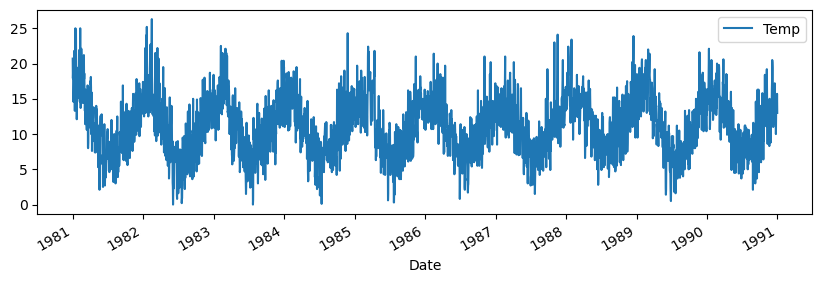

In [3]:
series_ad.plot(figsize=(10,3))
plt.show()

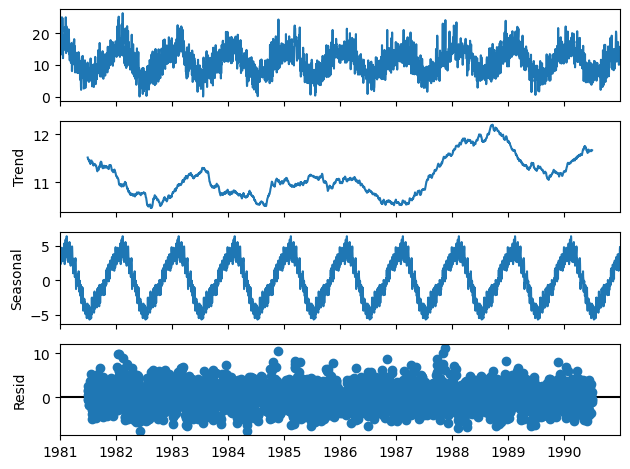

In [4]:
# periodo = int(len(series_ad)/2)
result_ad = seasonal_decompose(series_ad, model='additive', period=365)
result_ad.plot()
plt.show()

Comprobamos si el residuo es estacionario

In [5]:
print("p-value adfuller")
print(adfuller(result_ad.resid.dropna(), autolag='AIC')[1])
print("p-value kpss")
print(kpss(result_ad.resid.dropna())[1])


p-value adfuller
2.7078469688982655e-30
p-value kpss
0.1


C:\Users\icalvo\AppData\Local\Temp\ipykernel_13208\2305285553.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  print(kpss(result_ad.resid.dropna())[1])


Test de heterocedasticidad

In [ ]:
lm_test = het_arch(result_ad.resid.dropna())

print("Resultados del ARCH test:")
print(f"Estadístico LM: {lm_test[0]:.4f}")
print(f"P-valor LM: {lm_test[1]:.4f}")
print(f"Estadístico F: {lm_test[2]:.4f}")
print(f"P-valor F: {lm_test[3]:.4f}")

Resultados del ARCH test:
Estadístico LM: 474.1052
P-valor LM: 0.0000
Estadístico F: 1.6893
P-valor F: 0.0000


### 2. Serie multiplicativa

In [7]:
series_mul = pd.read_csv('airline-passengers.csv', header=0, index_col=0)
series_mul.head()

,Passengers
Month,
1949-01,112
1949-02,118
1949-03,132
1949-04,129
1949-05,121


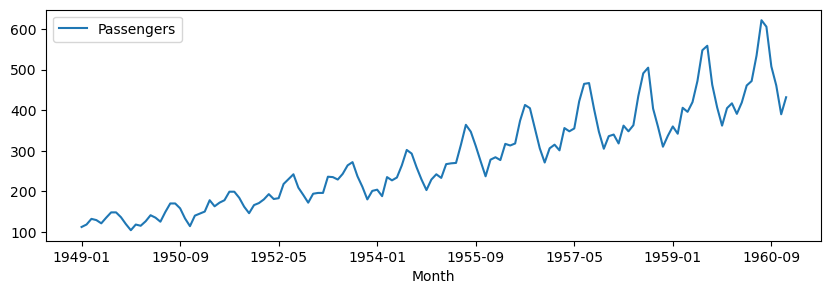

In [8]:
series_mul.plot(figsize=(10,3))
plt.show()

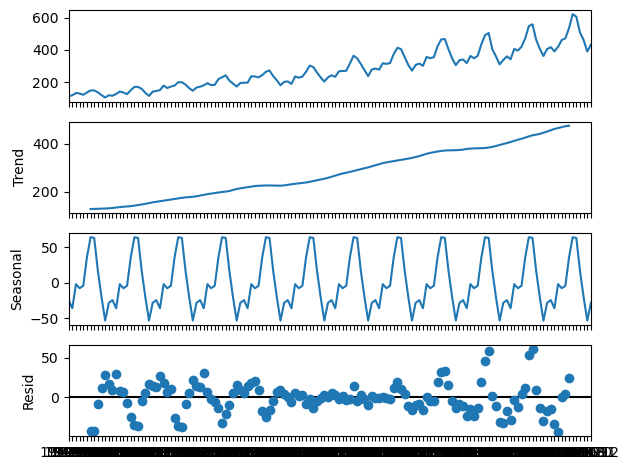

In [9]:
result_mul = seasonal_decompose(series_mul, model='additive', period=12)
result_mul.plot()
plt.show()

In [10]:
print("p-value adfuller")
print(adfuller(result_mul.resid.dropna(), autolag='AIC')[1])
print("p-value kpss")
print(kpss(result_mul.resid.dropna())[1])

p-value adfuller
5.5168689022264624e-06
p-value kpss
0.1


C:\Users\icalvo\AppData\Local\Temp\ipykernel_13208\740865306.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  print(kpss(result_mul.resid.dropna())[1])


Test de heterocedaticidad   

In [11]:

lm_test = het_arch(result_mul.resid.dropna())

print("Resultados del ARCH test:")
print(f"Estadístico LM: {lm_test[0]:.4f}")
print(f"P-valor LM: {lm_test[1]:.4f}")
print(f"Estadístico F: {lm_test[2]:.4f}")
print(f"P-valor F: {lm_test[3]:.4f}")

Resultados del ARCH test:
Estadístico LM: 45.4267
P-valor LM: 0.0000
Estadístico F: 6.5850
P-valor F: 0.0000


Todos los p-valores son menores que el valor de significancia por lo que podemos rechazar la hipótesis nula y considerar que la serie presenta heterocedasticidad. Por lo tanto la serie no es estacionaria.